# Sprint 3 — Modelado: modelo base vs. Machine Learning
**Pedido del docente (Semana 3):** *un modelo de Machine Learning que ya haga predicciones* y una tabla comparativa
sencilla: *"El cálculo sencillo de la Semana 2 tenía un error del X%, mientras que este modelo tiene un error del Y%"*.

Se construyen dos modelos:
- **Objetivo 1 (principal):** ¿se matricula el inscrito? Se comparan el modelo base, la regresión logística, Random
  Forest y XGBoost.
- **Objetivo 2:** ¿pierde la beca al cerrar el primer semestre? Es la alerta temprana para becados.

| Sección | Contenido |
|---|---|
| 1 | Variables de entrada (sin fuga de datos) |
| 2 | Ajuste de hiperparámetros con validación temporal |
| 3 | Comparación final en la prueba 2026-2 |
| 4 | Pérdida de beca (objetivo 2) |
| 5 | Modelos finales y tabla de predicciones (bloque 3 del tablero) |

In [1]:
import sys
import warnings
from pathlib import Path

# Raíz del repositorio: se sube de carpeta hasta encontrar config/reglas_negocio.yaml
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config" / "reglas_negocio.yaml").exists())
sys.path.insert(0, str(RAIZ / "src"))
warnings.filterwarnings("ignore")
EN_COLAB = False
SPRINTS = RAIZ / "sprints"

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", "{:,.3f}".format)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
AZUL, NARANJA, GRIS = "#1B365D", "#E07B39", "#9AA5B1"

In [3]:
import caracteristicas as ca
import flujo
import modelado as mo

# Lee las tablas planas por la API de Supabase (solo lectura) y construye las columnas del Sprint 2
f = flujo.cargar_y_construir("supabase" if EN_COLAB else "auto")
d, p, ref, cfg = f["inscritos"], f["permanencia"], f["referencias"], ca.configuracion()
print("Origen de los datos:", f["origen"])
print(f"Inscritos: {len(d):,} · matriculados con el primer semestre cerrado: {len(p):,}")
print(d["particion"].value_counts().to_string())

Origen de los datos: Supabase (API de solo lectura)
Inscritos: 2,991 · matriculados con el primer semestre cerrado: 837
particion
ENTRENAMIENTO    1310
PRUEBA            761
VALIDACION        504
CAMPANA           416


## 1. Variables de entrada
Solo se usan datos que existen **antes** de la decisión que se predice. Por ejemplo, los documentos entregados o la
forma de financiación no entran: se conocen al matricularse y serían fuga de datos.
Se agregan dos variables simples: `icfes_al_cuadrado`, para que la regresión logística pueda captar la "U invertida"
del Saber 11, y `semestre_2`, el ingreso a mitad de año.

In [4]:
V, Vb = mo.VARIABLES_MATRICULA, mo.VARIABLES_BECA
display(pd.DataFrame([(tipo, ", ".join(cols)) for tipo, cols in V.items()], columns=["tipo", "variables (matrícula)"]))
display(pd.DataFrame([(tipo, ", ".join(cols)) for tipo, cols in Vb.items()], columns=["tipo", "variables (pérdida de beca)"]))
y = lambda x, col="matriculado": x[col].astype(int)
X = lambda x, v=V: mo.preparar_X(x, ref, v)
e, v, t = (flujo.conjunto(d, c) for c in ["ENTRENAMIENTO", "VALIDACION", "PRUEBA"])
ev = flujo.conjunto(d, "ENTRENAMIENTO", "VALIDACION")
print(f"Entrenamiento {len(e)} · validación {len(v)} · prueba {len(t)} inscritos")

,tipo,variables (matrícula)
0,numericas,"punt_global, icfes_al_cuadrado, promedio_acumu..."
1,binarias,"entrevista_realizada, apoyo_foes, elegible_foe..."
2,categoricas,"programa, genero, canal, beca, tipo_colegio, r..."


,tipo,variables (pérdida de beca)
0,numericas,"punt_global, promedio_acumulado_colegio, prome..."
1,binarias,"colegio_privado, semestre_2"
2,categoricas,"programa, genero, beca, tipo_colegio, segmento..."


Entrenamiento 1310 · validación 504 · prueba 761 inscritos


## 2. Ajuste de hiperparámetros con validación temporal
Cada modelo tiene "perillas" (hiperparámetros): la regularización C de la regresión logística, la profundidad de los
árboles en Random Forest, la tasa de aprendizaje en XGBoost. Cada combinación se **entrena con 2024-1 a 2025-2 y se
mide en 2026-1**. Se elige la de menor **log-loss**, que castiga más las probabilidades seguras que salen mal.
Si un modelo más simple queda a menos de 0,002 del mejor, se prefiere el simple (navaja de Occam).

In [5]:
COMPLEJIDAD = ["logistica", "random_forest", "xgboost"]
busquedas = {tipo: mo.ajustar_temporal(tipo, cfg, X(e), y(e), X(v), y(v), V) for tipo in COMPLEJIDAD}
for tipo, b in busquedas.items():
    print(f"\n{tipo}: {len(b)} combinaciones probadas; las 3 mejores en validación 2026-1")
    display(b.drop(columns="parametros").head(3).round(4))
mejores = {tipo: b.iloc[0] for tipo, b in busquedas.items()}
minimo = min(m["log_loss_validacion"] for m in mejores.values())
elegido = next(tp for tp in COMPLEJIDAD if mejores[tp]["log_loss_validacion"] <= minimo + 0.002)
print(f"\nModelo elegido por validación: {elegido} {mejores[elegido]['parametros']}")


logistica: 4 combinaciones probadas; las 3 mejores en validación 2026-1


,tipo,param_C,log_loss_validacion,auc_validacion,brier_validacion,error_pct_validacion
0,logistica,0.010,0.637,0.678,0.223,36.309
1,logistica,0.100,0.639,0.681,0.224,35.913
2,logistica,1.000,0.647,0.680,0.227,35.714



random_forest: 16 combinaciones probadas; las 3 mejores en validación 2026-1


,tipo,param_max_depth,param_min_samples_leaf,param_max_features,log_loss_validacion,auc_validacion,brier_validacion,error_pct_validacion
0,random_forest,6.000,5,sqrt,0.640,0.673,0.225,36.111
1,random_forest,4.000,5,sqrt,0.641,0.674,0.225,36.508
2,random_forest,8.000,5,sqrt,0.641,0.673,0.225,36.905



xgboost: 12 combinaciones probadas; las 3 mejores en validación 2026-1


,tipo,param_n_estimators,param_max_depth,param_learning_rate,param_min_child_weight,log_loss_validacion,auc_validacion,brier_validacion,error_pct_validacion
0,xgboost,200,2,0.030,5,0.645,0.666,0.227,36.309
1,xgboost,200,3,0.030,5,0.652,0.656,0.230,37.897
2,xgboost,400,2,0.030,5,0.653,0.657,0.230,38.492



Modelo elegido por validación: logistica {'C': 0.01}


**Lectura.** Los tres modelos quedan muy cerca. La regresión logística gana o empata: la relación entre las variables
y la matrícula es casi lineal en log-odds, y en ese caso los árboles no tienen patrones complejos que aprovechar y
corren más riesgo de sobreajustarse.

## 3. Comparación final en la prueba 2026-2
Cada modelo se reentrena con entrenamiento + validación y se evalúa **una sola vez** en 2026-2, un periodo que no se
usó para elegir nada.
- **Error %:** inscritos mal clasificados con umbral de 50%.
- **AUC:** probabilidad de que el modelo ponga a un matriculado por encima de un no matriculado; 0,5 es azar.
- **Brier:** error cuadrático de la probabilidad; más bajo es mejor.

In [6]:
m_base = cfg["caracteristicas"]["peso_previo_modelo_base"]
probs = {"Clase mayoritaria": mo.ClaseMayoritaria().fit(ev, ev["matriculado"]).predict_proba(t)[:, 1],
         "Modelo base (Sprint 2)": mo.ModeloBase(m=m_base).fit(ev, ev["matriculado"]).predict_proba(t)[:, 1]}
NOMBRES = {"logistica": "Regresión logística", "random_forest": "Random Forest", "xgboost": "XGBoost"}
for tipo in COMPLEJIDAD:
    modelo = mo.construir_pipeline(tipo, mejores[tipo]["parametros"], V, cfg["modelado"]["semilla"]).fit(X(ev), y(ev))
    probs[NOMBRES[tipo]] = modelo.predict_proba(X(t))[:, 1]
res = {n: mo.metricas(y(t), q) for n, q in probs.items()}
comparacion = mo.tabla_metricas(res)
display(comparacion[["n", "error_pct", "auc_roc", "auc_pr", "brier"]])
b, m = res["Modelo base (Sprint 2)"], res[NOMBRES[elegido]]
print(f"\nEl cálculo sencillo de la Semana 2 tenía un error del {b['error_pct']:.1f}%, mientras que el modelo de la Semana 3 "
      f"({NOMBRES[elegido]}) tiene un error del {m['error_pct']:.1f}% en los inscritos de 2026-2.")
from sklearn.metrics import roc_auc_score
ic = mo.intervalo_bootstrap(y(t), probs[NOMBRES[elegido]], lambda a, q, u: roc_auc_score(a, q))
print(f"AUC del modelo elegido: {m['auc_roc']:.3f} (IC 95% por bootstrap: {ic[0]:.3f} a {ic[1]:.3f})")

,n,error_pct,auc_roc,auc_pr,brier
Clase mayoritaria,761.000,44.547,0.500,0.446,0.247
Modelo base (Sprint 2),761.000,42.181,0.622,0.541,0.237
Regresión logística,761.000,38.239,0.663,0.575,0.228
Random Forest,761.000,39.028,0.648,0.569,0.232
XGBoost,761.000,38.371,0.661,0.573,0.229



El cálculo sencillo de la Semana 2 tenía un error del 42.2%, mientras que el modelo de la Semana 3 (Regresión logística) tiene un error del 38.2% en los inscritos de 2026-2.


AUC del modelo elegido: 0.663 (IC 95% por bootstrap: 0.624 a 0.699)


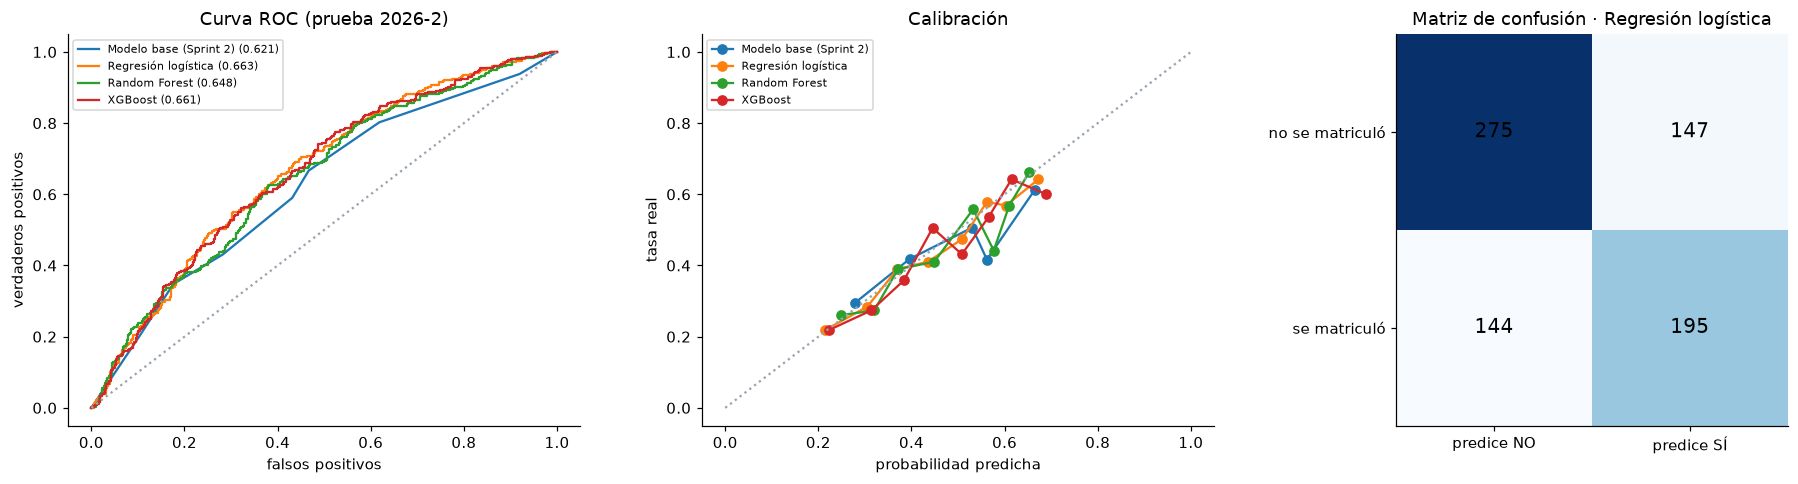

In [7]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import confusion_matrix, roc_curve
fig, ejes = plt.subplots(1, 3, figsize=(17, 4.5))
for n, q in probs.items():
    if n == "Clase mayoritaria":
        continue
    fpr, tpr, _ = roc_curve(y(t), q); ejes[0].plot(fpr, tpr, label=f"{n} ({res[n]['auc_roc']:.3f})")
    fr, me = calibration_curve(y(t), q, n_bins=8, strategy="quantile"); ejes[1].plot(me, fr, "o-", label=n)
ejes[0].plot([0, 1], [0, 1], ":", color=GRIS); ejes[0].set(title="Curva ROC (prueba 2026-2)", xlabel="falsos positivos", ylabel="verdaderos positivos")
ejes[1].plot([0, 1], [0, 1], ":", color=GRIS); ejes[1].set(title="Calibración", xlabel="probabilidad predicha", ylabel="tasa real")
for ax in ejes[:2]:
    ax.legend(fontsize=7)
cm = confusion_matrix(y(t), probs[NOMBRES[elegido]] >= 0.5)
ejes[2].imshow(cm, cmap="Blues")
for (i, j), val in np.ndenumerate(cm):
    ejes[2].text(j, i, val, ha="center", va="center", fontsize=13)
ejes[2].set_xticks([0, 1], ["predice NO", "predice SÍ"]); ejes[2].set_yticks([0, 1], ["no se matriculó", "se matriculó"])
ejes[2].set_title(f"Matriz de confusión · {NOMBRES[elegido]}")
plt.tight_layout(); plt.show()

**Lectura.**
- El modelo supera al cálculo sencillo y a la referencia mínima, aunque sigue equivocándose en cerca de 4 de cada 10
  inscritos. La decisión de matricularse depende de factores que no están en los datos (familia, otras ofertas,
  trabajo).
- Su valor está en **ordenar**: a los de mayor probabilidad se les asegura la matrícula y a los indecisos se les hace
  seguimiento (Sprint 5).
- Las curvas de calibración cerca de la diagonal indican que un 60% predicho significa cerca de 60% real.

## 4. Objetivo 2: ¿perderá la beca en el primer semestre?
Hay 557 becados con el primer semestre cerrado. Como son pocos, los hiperparámetros se eligen con **validación cruzada
de 5 pliegues** dentro del entrenamiento (2024-1 a 2025-2). La prueba es 2026-1, porque la cohorte 2026-2 aún no
cierra semestre. **No se usa el promedio del primer semestre**: es justamente lo que define si se pierde la beca.

In [8]:
bec = p[p["becado"] == 1]
eb, tb = flujo.conjunto(bec, "ENTRENAMIENTO"), flujo.conjunto(bec, "VALIDACION")
yb = lambda x: x["perdio_beca_semestre_1"].astype(int)
cv = {tipo: mo.ajustar_cv(tipo, cfg, X(eb, Vb), yb(eb), Vb) for tipo in COMPLEJIDAD}
mejores_b = {tipo: r.iloc[0] for tipo, r in cv.items()}
minimo_b = min(m["log_loss_cv"] for m in mejores_b.values())
elegido_b = next(tp for tp in COMPLEJIDAD if mejores_b[tp]["log_loss_cv"] <= minimo_b + 0.002)
probs_b = {"Clase mayoritaria": mo.ClaseMayoritaria().fit(eb, eb["perdio_beca_semestre_1"]).predict_proba(tb)[:, 1],
           "Modelo base (beca × segmento ICFES)": mo.ModeloBase(grupo=("beca", "segmento_rendimiento_icfes"), m=m_base)
                                                    .fit(eb, eb["perdio_beca_semestre_1"]).predict_proba(tb)[:, 1]}
for tipo in COMPLEJIDAD:
    probs_b[NOMBRES[tipo]] = mo.construir_pipeline(tipo, mejores_b[tipo]["parametros"], Vb, cfg["modelado"]["semilla"]) \
        .fit(X(eb, Vb), yb(eb)).predict_proba(X(tb, Vb))[:, 1]
res_b = {n: mo.metricas(yb(tb), q) for n, q in probs_b.items()}
display(mo.tabla_metricas(res_b)[["n", "error_pct", "auc_roc", "brier", "precision", "recall"]])
orden = np.argsort(-probs_b[NOMBRES[elegido_b]]); yt = yb(tb).to_numpy()[orden]
cortes = pd.DataFrame([{"% marcado": f"{q:.0%}", "becados marcados": round(q * len(yt)),
                        "% que sí perdió la beca": yt[: round(q * len(yt))].mean()} for q in [0.1, 0.2, 0.3, 0.4, 0.5]])
print(f"Elegido por validación cruzada: {NOMBRES[elegido_b]}. Tasa general de pérdida en 2026-1: {yt.mean():.0%}")
display(cortes.round(3))

,n,error_pct,auc_roc,brier,precision,recall
Clase mayoritaria,140.000,42.857,0.500,0.247,0.571,1.000
Modelo base (beca × segmento ICFES),140.000,37.857,0.622,0.235,0.652,0.725
Regresión logística,140.000,37.857,0.686,0.224,0.617,0.887
Random Forest,140.000,39.286,0.658,0.228,0.613,0.850
XGBoost,140.000,37.143,0.635,0.234,0.630,0.850


Elegido por validación cruzada: Regresión logística. Tasa general de pérdida en 2026-1: 57%


,% marcado,becados marcados,% que sí perdió la beca
0,10%,14,0.786
1,20%,28,0.714
2,30%,42,0.738
3,40%,56,0.750
4,50%,70,0.743


**Lectura.** Con pocos datos, la incertidumbre es grande (la prueba tiene 140 becados) y el resultado es **modesto**:
cuando el modelo marca al 10% de mayor riesgo, cerca de 8 de cada 10 sí pierden la beca, frente a la tasa general (cerca
de 6 de cada 10), pero el intervalo del AUC es ancho. Con estos datos, la alerta de beca sirve como apoyo, no para
decidir sola a quién dar tutoría. El modelo se elige con la validación cruzada (si dos empatan, el más simple), antes de
mirar la prueba.

## 5. Modelos finales y tabla de predicciones (bloque 3 del tablero)
El modelo elegido se reentrena con **todo el histórico** (2024-1 a 2026-2) para predecir la campaña 2027-1. La tabla
`prediccion` (también en Supabase) tiene, por inscrito, la probabilidad de matrícula, el decil, el segmento de
propensión y, si tiene beca, la probabilidad de perderla.

In [9]:
hist = flujo.conjunto(d, "ENTRENAMIENTO", "VALIDACION", "PRUEBA")
final = mo.construir_pipeline(elegido, mejores[elegido]["parametros"], V, cfg["modelado"]["semilla"]).fit(X(hist), y(hist))
final_b = mo.construir_pipeline(elegido_b, mejores_b[elegido_b]["parametros"], Vb, cfg["modelado"]["semilla"]).fit(X(bec, Vb), yb(bec))
pm, pb = final.predict_proba(X(d))[:, 1].round(4), final_b.predict_proba(X(d, Vb))[:, 1]
s = cfg["modelado"]["segmentos_propension"]
prediccion = pd.DataFrame({"inscripcion_id": d["inscripcion_id"], "periodo": d["periodo"], "prob_matricula": pm,
                           "segmento_propension": np.select([pm >= s["ALTA"], pm < s["BAJA"]], ["ALTA", "BAJA"], "MEDIA"),
                           "prob_perdida_beca": np.where(d["beca"] != "NINGUNA", pb.round(4), np.nan)})
display(prediccion[prediccion["periodo"] == "2027-1"].sort_values("prob_matricula", ascending=False).head(10))
print(prediccion.groupby("periodo")["segmento_propension"].value_counts().unstack().fillna(0).astype(int))

,inscripcion_id,periodo,prob_matricula,segmento_propension,prob_perdida_beca
1462,1463,2027-1,0.775,ALTA,0.733
45,46,2027-1,0.775,ALTA,0.625
762,763,2027-1,0.757,ALTA,0.599
2613,2614,2027-1,0.749,ALTA,0.542
760,761,2027-1,0.747,ALTA,0.548
642,643,2027-1,0.736,ALTA,0.577
1426,1427,2027-1,0.731,ALTA,0.631
1364,1365,2027-1,0.723,ALTA,0.632
1234,1235,2027-1,0.723,ALTA,0.695
1540,1541,2027-1,0.722,ALTA,0.524


segmento_propension  ALTA  BAJA  MEDIA
periodo                               
2024-1                 76    81    201
2024-2                 45    56    106
2025-1                103   134    225
2025-2                 69    76    138
2026-1                 98   155    251
2026-2                131   206    424
2027-1                 99   110    207


## Conclusiones del Sprint 3
1. El modelo de Machine Learning **ya predice** y supera al cálculo sencillo de la Semana 2 en error, AUC y Brier.
2. La regresión logística queda por delante de Random Forest y XGBoost: más simple, igual o más exacta y más fácil de
   explicar. Se elige con evidencia, no por preferencia.
3. La alerta de pérdida de beca es **modesta** con estos datos: ordena mejor que decir "todos la pierden", pero con
   pocos becados su incertidumbre es grande. Se reporta tal cual, como límite del proyecto.
4. Los modelos finales quedan guardados (`sprints/sprint_3_modelado/modelos/`) y los usan los sprints 4 a 6.